# 05: Model interpretation

Notebook 04 told us which model wins on which metric. This notebook asks the more interesting question: **what did the models actually learn?** For a beginner project the metrics matter less than this. If a model achieves 0.65 AUC but its top features make biological sense, you have a working pipeline. If it achieves 0.65 AUC by latching onto an artefact, you have a bug.

We do three things:

1. Reshape the **logistic regression** coefficients back to a (position × amino acid) matrix and read it as a heatmap. Each cell is the contribution of "amino acid X at position P" to the log-odds of being immunogenic.
2. Aggregate the **random forest** feature importances by position and by amino acid, since position-by-amino-acid is too noisy for a tree ensemble.
3. Cross-reference the result against MHC class I biology: positions 2 and 9 (PΩ) are anchor residues that bind the MHC groove; positions 4 to 7 face outward and contact the T-cell receptor. If the models pick up signal from the right positions, that is a sanity check on the whole pipeline.

In [1]:
import numpy as np
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

MAX_LEN = 11
N_AA    = 21
AA_LIST = list('ACDEFGHIKLMNPQRSTVWY')
AA_LABELS = AA_LIST + ['-']  # 21st column is the padding token

MODEL_DIR = Path('..') / 'outputs' / 'models'
FIG_DIR   = Path('..') / 'outputs'

## 1. Logistic regression coefficients

The LR model has 231 features arranged as (position 1 AA A, position 1 AA C, ..., position 11 AA -). That layout matches the encoding in notebook 02: outer index is position, inner index is amino acid.

Each coefficient is the change in log-odds of being immunogenic when that one feature flips from 0 to 1. **Positive (red) means the amino acid at that position pushes the model toward predicting immunogenic; negative (blue) means it pushes toward non-immunogenic.** Magnitude shows how strong the effect is. White means the model is indifferent.

In [2]:
lr = joblib.load(MODEL_DIR / 'logistic_regression.joblib')

# coef_ has shape (1, 231) for binary LR; reshape to (11, 21).
coef = lr.coef_.reshape(MAX_LEN, N_AA)
print(f'Coefficient matrix shape: {coef.shape}')
print(f'Range: [{coef.min():.3f}, {coef.max():.3f}]')

Coefficient matrix shape: (11, 21)
Range: [-0.680, 0.856]


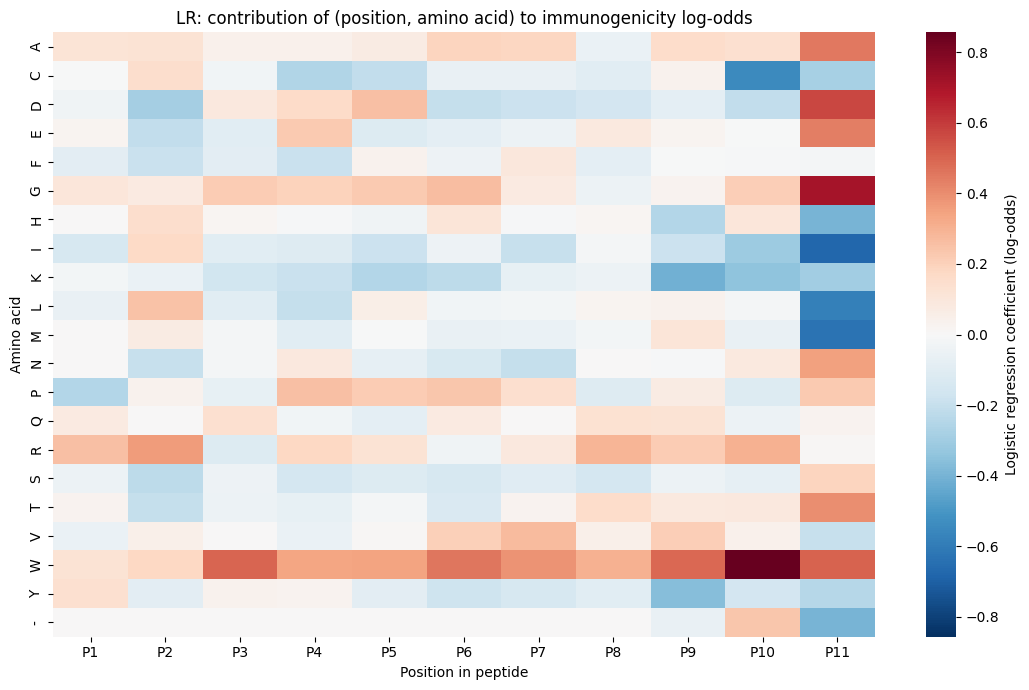

In [3]:
fig, ax = plt.subplots(figsize=(11, 7))
limit = max(abs(coef.min()), abs(coef.max()))
sns.heatmap(
    coef.T, ax=ax,
    xticklabels=[f'P{i+1}' for i in range(MAX_LEN)],
    yticklabels=AA_LABELS,
    cmap='RdBu_r', center=0, vmin=-limit, vmax=limit,
    cbar_kws={'label': 'Logistic regression coefficient (log-odds)'},
)
ax.set_xlabel('Position in peptide')
ax.set_ylabel('Amino acid')
ax.set_title('LR: contribution of (position, amino acid) to immunogenicity log-odds')
plt.tight_layout()
plt.savefig(FIG_DIR / 'lr_coefficient_heatmap.png', dpi=150)
plt.show()

### Reading the heatmap

Three things to look for:

- **Strong vertical bands** at certain positions mean the model has learned that *that position matters a lot*: many amino acids at that position have non-zero coefficients. Faint columns mean the model treats those positions as roughly interchangeable.
- **Specific (position, AA) cells with large magnitude** are the model's strongest single rules. Cross-reference these against what you know: aromatic and hydrophobic residues (F, Y, W, L, V, I, M) at P2 and PΩ are the canonical MHC-I anchor preferences.
- **The padding row (`-`) at later positions** should have moderate coefficients reflecting the fact that shorter peptides (8/9/10-mers) have padding there, and shorter peptides may differ systematically in immunogenicity from 11-mers. This is an artefact of the right-padding choice; center-padding would push padding into the middle and probably weaken these signals.

We extract the top contributors below.

In [4]:
rows = []
for p in range(MAX_LEN):
    for a, aa in enumerate(AA_LABELS):
        rows.append({'position': p + 1, 'amino_acid': aa, 'coef': coef[p, a]})
coef_df = pd.DataFrame(rows)

print('Top 10 features pushing TOWARD immunogenic (positive coef):')
print(coef_df.nlargest(10, 'coef').to_string(index=False))
print()
print('Top 10 features pushing AWAY from immunogenic (negative coef):')
print(coef_df.nsmallest(10, 'coef').to_string(index=False))

Top 10 features pushing TOWARD immunogenic (positive coef):
 position amino_acid     coef
       10          W 0.855925
       11          G 0.714930
       11          D 0.572317
       11          W 0.502866
        3          W 0.496590
        9          W 0.488822
        6          W 0.458107
       11          A 0.450952
       11          E 0.440879
       11          T 0.397055

Top 10 features pushing AWAY from immunogenic (negative coef):
 position amino_acid      coef
       11          I -0.679950
       11          M -0.631186
       11          L -0.585008
       10          C -0.547394
        9          K -0.409573
       11          - -0.400695
       11          H -0.394659
        9          Y -0.366488
       10          K -0.341715
       10          I -0.310277


## 2. Random forest feature importances

RF importance is the total reduction in Gini impurity across all trees, averaged. Unlike LR coefficients it has no sign; it tells you a feature was useful for splitting, not whether it pushes the prediction up or down.

Plotting all 231 importances directly is noisy and hard to read. We aggregate two ways: **importance summed by position** (which positions matter overall?) and **importance summed by amino acid** (which residues matter overall?).

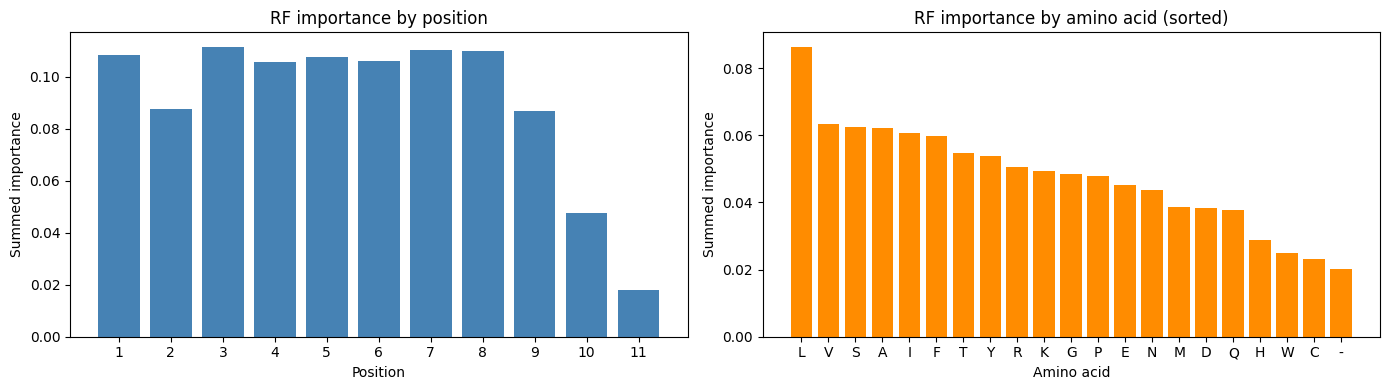

In [5]:
rf = joblib.load(MODEL_DIR / 'random_forest.joblib')
imp = rf.feature_importances_.reshape(MAX_LEN, N_AA)

by_position = imp.sum(axis=1)
by_aa       = imp.sum(axis=0)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].bar(range(1, MAX_LEN + 1), by_position, color='steelblue')
axes[0].set_xlabel('Position')
axes[0].set_ylabel('Summed importance')
axes[0].set_title('RF importance by position')
axes[0].set_xticks(range(1, MAX_LEN + 1))

order = np.argsort(by_aa)[::-1]
axes[1].bar([AA_LABELS[i] for i in order], by_aa[order], color='darkorange')
axes[1].set_xlabel('Amino acid')
axes[1].set_ylabel('Summed importance')
axes[1].set_title('RF importance by amino acid (sorted)')

plt.tight_layout()
plt.savefig(FIG_DIR / 'rf_importance_aggregated.png', dpi=150)
plt.show()

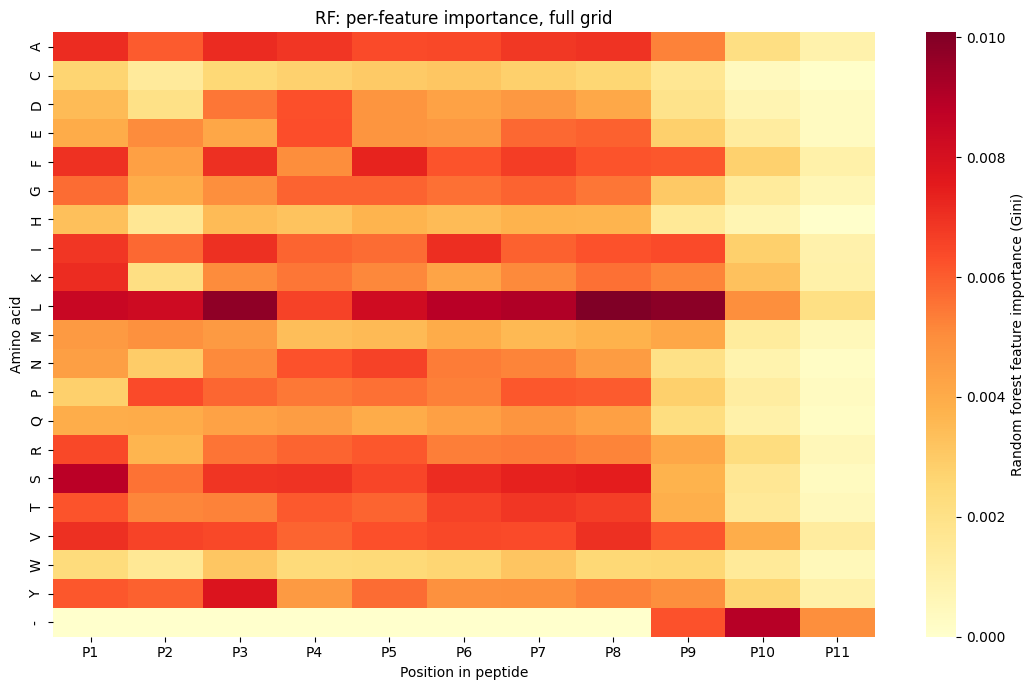

In [6]:
fig, ax = plt.subplots(figsize=(11, 7))
sns.heatmap(
    imp.T, ax=ax,
    xticklabels=[f'P{i+1}' for i in range(MAX_LEN)],
    yticklabels=AA_LABELS,
    cmap='YlOrRd', vmin=0,
    cbar_kws={'label': 'Random forest feature importance (Gini)'},
)
ax.set_xlabel('Position in peptide')
ax.set_ylabel('Amino acid')
ax.set_title('RF: per-feature importance, full grid')
plt.tight_layout()
plt.savefig(FIG_DIR / 'rf_importance_heatmap.png', dpi=150)
plt.show()

## 3. Reading both models against MHC class I biology

Here is what is known from structural biology, summarised:

| Position (in 9-mer) | Role                                            |
|---------------------|-------------------------------------------------|
| P2                  | Primary anchor; sits in MHC pocket B            |
| P9 (PΩ)             | Primary anchor; sits in MHC pocket F            |
| P3, P6              | Secondary anchors for some HLA alleles          |
| P4, P5, P7, P8      | Solvent-exposed; contact the T-cell receptor    |

Anchor residues drive **MHC binding**, not T-cell recognition per se. TCR contact residues drive **whether the peptide-MHC complex actually triggers a T-cell response**. Since our positives are experimentally verified to elicit a T-cell response (which requires both MHC binding and TCR engagement), the models could in principle pick up signal from either set.

**Things to compare against the plots:**

- If P2 and the C-terminal positions dominate the importance plots, the models are mostly learning **MHC binding preferences** (which makes sense, because IEDB negatives are skewed toward peptides that did not bind MHC well).
- If the TCR-contact positions (P4-P7) carry comparable weight, the models are picking up signal **beyond MHC binding**, closer to true immunogenicity.
- The right-padding choice in notebook 02 means PΩ is at position 8 for 8-mers, position 9 for 9-mers, position 10 for 10-mers, position 11 for 11-mers. This *dilutes* whatever PΩ signal exists, so any anchor signal we do see at P9-P11 is despite the encoding fighting us. This is part of the case for revisiting center-padding.

Notebook 06 turns this from observation into experiment: train the same models on TCR-contact positions only and see whether performance is preserved.

In [7]:
# Quick numeric summary that the markdown above refers to.
pos_summary = pd.DataFrame({
    'position':       range(1, MAX_LEN + 1),
    'lr_abs_sum':     np.abs(coef).sum(axis=1),
    'rf_importance':  by_position,
})
pos_summary['lr_rank'] = pos_summary['lr_abs_sum'].rank(ascending=False).astype(int)
pos_summary['rf_rank'] = pos_summary['rf_importance'].rank(ascending=False).astype(int)
print(pos_summary.round(3).to_string(index=False))

 position  lr_abs_sum  rf_importance  lr_rank  rf_rank
        1       1.585          0.108       11        4
        2       3.082          0.088        3        8
        3       1.920          0.112       10        1
        4       2.899          0.106        6        7
        5       2.518          0.108        7        5
        6       2.940          0.106        5        6
        7       2.397          0.110        8        2
        8       1.967          0.110        9        3
        9       3.010          0.087        4        9
       10       3.963          0.048        2       10
       11       7.621          0.018        1       11


## What the interpretation tells us, in plain terms

The interpretation step is not just a checkbox. It changes how we should read the metrics from notebook 04:

- If the top-ranked positions are biologically sensible (anchor positions or TCR-contact positions), then the moderate AUC is genuine signal, not artefact. The path to better performance is more data, better encoding (center-padding), or richer features (physicochemical properties).
- If the top-ranked positions are random or dominated by padding, the models found a shortcut and the metrics are misleading.
- The amino-acid-level ranking is a sanity check. If hydrophobic residues (L, V, I, M, F, Y, W) and basic residues (R, K) dominate, that is consistent with known MHC-I peptide preferences. If the dominant residues are the most common ones in the dataset (which would be visible in the EDA frequency plot from notebook 02), the model may just be reproducing the prior.

Notebook 06 follows the natural next question: if we **remove** the anchor positions from the input, does the model still work? If yes, immunogenicity has a lot of TCR-contact signal that does not depend on MHC binding strength. If no, what we are calling "immunogenicity prediction" is mostly "MHC binding prediction in disguise."